# 04 - LSMC valuation: total, intrinsic and extrinsic value

Least-Squares Monte Carlo for gas storage (Boogert & de Jong, 2008), built on Longstaff & Schwartz (2001).
The storage is now managed against the **spot** price with full flexibility: at every decision date the operator
chooses how much to inject or withdraw given the current price and inventory, knowing that the price mean-reverts
towards the forward curve.

**Dynamic programme.** With inventory $v$ on a volume grid and model state $X_{t_k}$,
$$\mathcal V_k(v,X_{t_k}) = \max_{\Delta v\in\mathcal A_k(v)}\Big[\pi(\Delta v;S_{t_k},D_k) + C_k(v+\Delta v, X_{t_k})\Big],
\qquad C_k(v',x) = \mathbb E\big[\mathcal V_{k+1}(v',X_{t_{k+1}})\mid X_{t_k}=x\big].$$

**Backward pass (regression paths).** For every step and every grid level $v'$, the realised values
$\mathcal V^{(n)}_{k+1}(v')$ are regressed on a basis of the state: polynomials of degree 3 in
$z = X_{t_k}/\sqrt{V(0,t_k)}$ by default, $\hat C_k(v',x) = \phi(x)^\top\hat\beta_k(v')$. The action maximises cash plus
the fitted continuation (linearly interpolated between grid levels), and the *realised* value is propagated backwards.

**Forward pass (independent valuation paths).** The policy $\{\hat\beta_k\}$ is applied from $v_0 = 0$ on paths that
were not used in the regressions:
$$\hat V = \frac1{N}\sum_{n=1}^{N}\sum_k \pi\big(\Delta v^{(n)}_k;S^{(n)}_{t_k},D_k\big),\qquad \mathrm{SE} = \hat s/\sqrt N.$$
The policy is feasible but sub-optimal (regression error, finite grid), so $\hat V$ estimates a **lower bound** of the
true value without bias. Settings (configuration): weekly steps, 101 volume levels, 10,000 regression paths
(seed 12345) and 10,000 valuation paths (seed 67890).

In [1]:
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir("..")

from gasstorage import plotting
from gasstorage.config import load_config
from gasstorage.models.one_factor import OneFactorModel
from gasstorage.storage.contract import build_inputs
from gasstorage.storage.dp import solve_dp
from gasstorage.storage.intrinsic import solve_lp
from gasstorage.storage.lsmc import lsmc_value, policy_map
from gasstorage.storage.rolling_intrinsic import rolling_intrinsic

plotting.apply_style()
CASES = {
    "market (EEX)": "configs/storage_default.yaml",
    "contango (SYNTHETIC)": "configs/storage_synthetic.yaml",
}
cfgs = {name: load_config(path) for name, path in CASES.items()}
mc = cfgs["market (EEX)"].monte_carlo
print(mc)


def run_lsmc(inp, model, n_reg, n_val, seed_reg, seed_val, **kw):
    return lsmc_value(
        inp,
        model,
        n_reg,
        n_val,
        np.random.default_rng(seed_reg),
        np.random.default_rng(seed_val),
        **kw,
    )

MonteCarloConfig(time_step='weekly', n_paths_regression=10000, n_paths_valuation=10000, seed_regression=12345, seed_valuation=67890, volume_grid_size=101, basis='polynomial', basis_degree=3)


## 1. Headline values

In [2]:
results, rows = {}, {}
for name, cfg in cfgs.items():
    inp = build_inputs(cfg, mc.time_step)
    model = OneFactorModel.from_config(cfg.model)
    t0 = time.perf_counter()
    res = run_lsmc(
        inp,
        model,
        mc.n_paths_regression,
        mc.n_paths_valuation,
        mc.seed_regression,
        mc.seed_valuation,
        n_levels=mc.volume_grid_size,
        basis=mc.basis,
        degree=mc.basis_degree,
    )
    elapsed = time.perf_counter() - t0
    intr_grid = solve_dp(
        inp.contract, inp.prices, inp.days, inp.discount, n_levels=mc.volume_grid_size
    ).value
    intr_milp = solve_lp(inp.contract, inp.prices, inp.days, inp.discount, ratchets=True).value
    ri = rolling_intrinsic(
        inp, model, 2000, np.random.default_rng(2027), n_levels=mc.volume_grid_size
    )
    results[name] = (inp, model, res, intr_grid, ri)
    rows[name] = {
        "LSMC total": res.value,
        "SE": res.se,
        "intrinsic (DP, same grid)": intr_grid,
        "extrinsic = total - intrinsic": res.value - intr_grid,
        "extrinsic share (%)": 100 * (res.value - intr_grid) / res.value,
        "intrinsic (weekly MILP, exact)": intr_milp,
        "rolling intrinsic (2,000 paths)": ri.value,
        "RI SE": ri.se,
        "in-sample LSMC (regression paths)": res.in_sample_value,
        "LSMC run time (s)": elapsed,
    }
headline = pd.DataFrame(rows)
fmt = headline.copy()
money = [r for r in fmt.index if r not in ("extrinsic share (%)", "LSMC run time (s)")]
fmt.loc[money] = fmt.loc[money] / 1e6
fmt.round(3).rename(index=lambda r: r + (" [MEUR]" if r in money else ""))

,market (EEX),contango (SYNTHETIC)
LSMC total [MEUR],4.895,7.980
SE [MEUR],0.058,0.055
"intrinsic (DP, same grid) [MEUR]",0.000,6.434
extrinsic = total - intrinsic [MEUR],4.895,1.546
extrinsic share (%),100.000,19.368
"intrinsic (weekly MILP, exact) [MEUR]",0.000,6.540
"rolling intrinsic (2,000 paths) [MEUR]",3.528,7.620
RI SE [MEUR],0.118,0.128
in-sample LSMC (regression paths) [MEUR],4.872,8.001
LSMC run time (s),22.182,21.675


**Reading the table.**

* *Extrinsic* is measured against the intrinsic value on the same weekly 101-level grid, so that grid discretisation
  cancels; the exact weekly MILP is shown alongside.
* The in-sample estimate (computed on the regression paths) and the out-of-sample estimate agree to Monte Carlo error:
  no sign of overfitting of the regressions. The out-of-sample number is the one reported.
* Rolling intrinsic sits between intrinsic and LSMC: re-optimising monthly against forwards captures part of the
  optionality; reacting to the spot every week captures the rest.

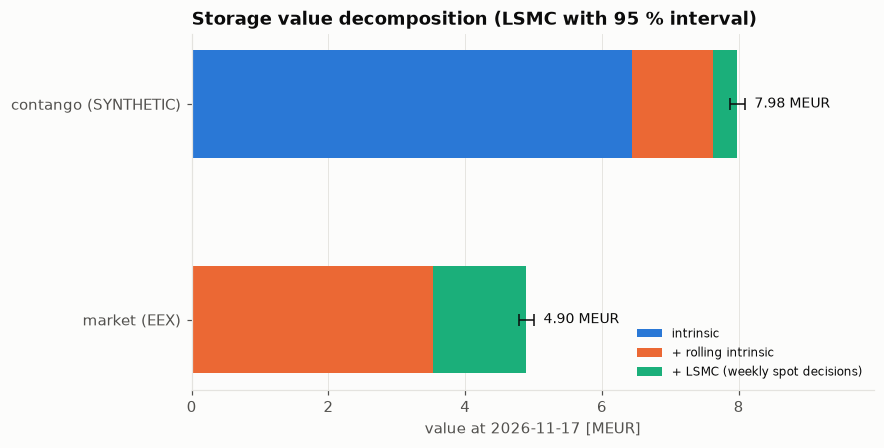

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.2))
names = list(results)
intr = np.array([results[n][3] for n in names]) / 1e6
ri_inc = np.array([results[n][4].value - results[n][3] for n in names]) / 1e6
ls_inc = np.array([results[n][2].value - results[n][4].value for n in names]) / 1e6
se = np.array([results[n][2].se for n in names]) / 1e6
y = np.arange(len(names))
ax.barh(y, intr, color=plotting.SERIES[0], height=0.5, label="intrinsic")
ax.barh(y, ri_inc, left=intr, color=plotting.SERIES[1], height=0.5, label="+ rolling intrinsic")
ax.barh(
    y,
    ls_inc,
    left=intr + ri_inc,
    color=plotting.SERIES[2],
    height=0.5,
    label="+ LSMC (weekly spot decisions)",
)
total = intr + ri_inc + ls_inc
ax.errorbar(total, y, xerr=1.96 * se, fmt="none", ecolor=plotting.TEXT_PRIMARY, capsize=4, lw=1)
for yi, t in zip(y, total, strict=True):
    ax.text(t + 0.25, yi, f"{t:.2f} MEUR", va="center", fontsize=9, color=plotting.TEXT_PRIMARY)
ax.set_yticks(y, names)
ax.set_xlabel("value at 2026-11-17 [MEUR]")
ax.set_xlim(0, total.max() * 1.25)
ax.set_title("Storage value decomposition (LSMC with 95 % interval)")
ax.legend(loc="lower right", fontsize=8)
ax.grid(axis="y", visible=False)
plotting.save_figure(fig, "04_value_decomposition")
fig

## 2. Optimal inventory and P&L distribution

Inventory paths of the LSMC policy on the 10,000 valuation paths, with the intrinsic schedule for reference.

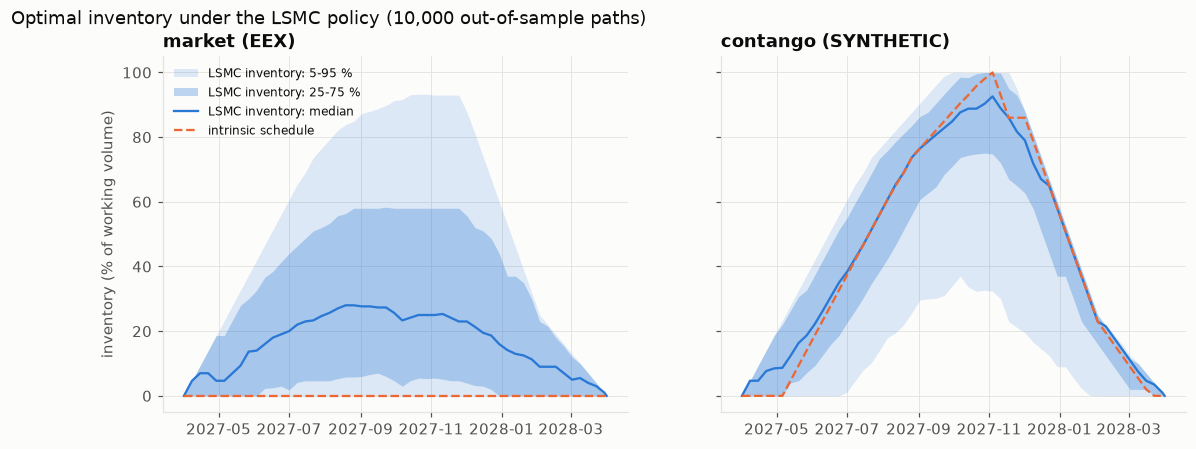

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, name in zip(axes, results, strict=True):
    inp, model, res, _, _ = results[name]
    dates = inp.dates.append(
        pd.DatetimeIndex([inp.dates[-1] + pd.Timedelta(days=int(inp.days[-1]))])
    )
    vol = inp.contract.working_volume
    plotting.fan_chart(ax, dates, 100 * res.inventory / vol, label="LSMC inventory")
    intr = solve_dp(inp.contract, inp.prices, inp.days, inp.discount, n_levels=101)
    ax.plot(
        dates,
        100 * intr.inventory / vol,
        color=plotting.SERIES[1],
        lw=1.5,
        ls="--",
        label="intrinsic schedule",
    )
    ax.set_title(name)
axes[0].set_ylabel("inventory (% of working volume)")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle(
    "Optimal inventory under the LSMC policy (10,000 out-of-sample paths)", x=0.01, ha="left"
)
plotting.save_figure(fig, "04_inventory_fan")
fig

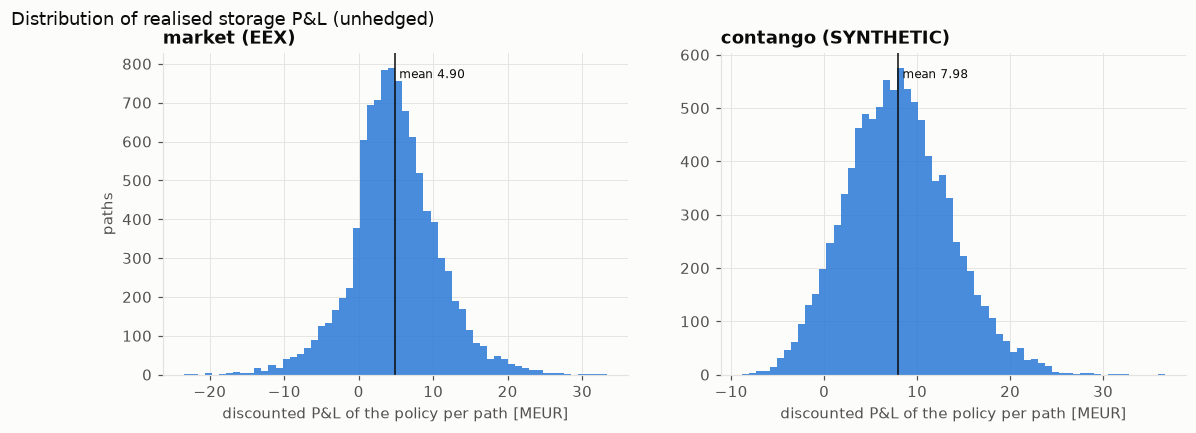

,market (EEX),contango (SYNTHETIC)
mean,4.895,7.980
std,5.785,5.516
5 % quantile,-4.627,-0.736
ES 5 %,-8.000,-2.501
P(P&L < 0) %,14.780,6.680


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
stats = {}
for ax, name in zip(axes, results, strict=True):
    res = results[name][2]
    pv = res.path_values / 1e6
    ax.hist(pv, bins=60, color=plotting.SERIES[0], alpha=0.85)
    ax.axvline(pv.mean(), color=plotting.TEXT_PRIMARY, lw=1)
    ax.text(pv.mean(), ax.get_ylim()[1] * 0.95, f" mean {pv.mean():.2f}", fontsize=8, va="top")
    ax.set_title(name)
    ax.set_xlabel("discounted P&L of the policy per path [MEUR]")
    q5 = np.quantile(pv, 0.05)
    stats[name] = {
        "mean": pv.mean(),
        "std": pv.std(),
        "5 % quantile": q5,
        "ES 5 %": pv[pv <= q5].mean(),
        "P(P&L < 0) %": 100 * (pv < 0).mean(),
    }
axes[0].set_ylabel("paths")
fig.suptitle("Distribution of realised storage P&L (unhedged)", x=0.01, ha="left")
plotting.save_figure(fig, "04_pnl_distribution")
display(fig)
pd.DataFrame(stats).round(3)

The spread of the unhedged P&L is wide compared with its mean: the operator buys and sells physical gas at
the spot, so the realised P&L depends on where prices go. The *value* is the mean; the dispersion is the risk that the
delta hedge of notebook 05 removes.

## 3. What the policy does

Optimal weekly move as a function of the spot price and the inventory, for the market case, on a summer and a winter
date. Blue: injection, red: withdrawal, grey: hold. The boundaries between the regions are the exercise boundaries of
the storage option; they move with the time of year, the remaining time and the ratchets. Regions that the policy
almost never visits (e.g. a full storage at low prices in January on the market curve) rest on regression
extrapolation and can look striped; they carry little weight in the value.

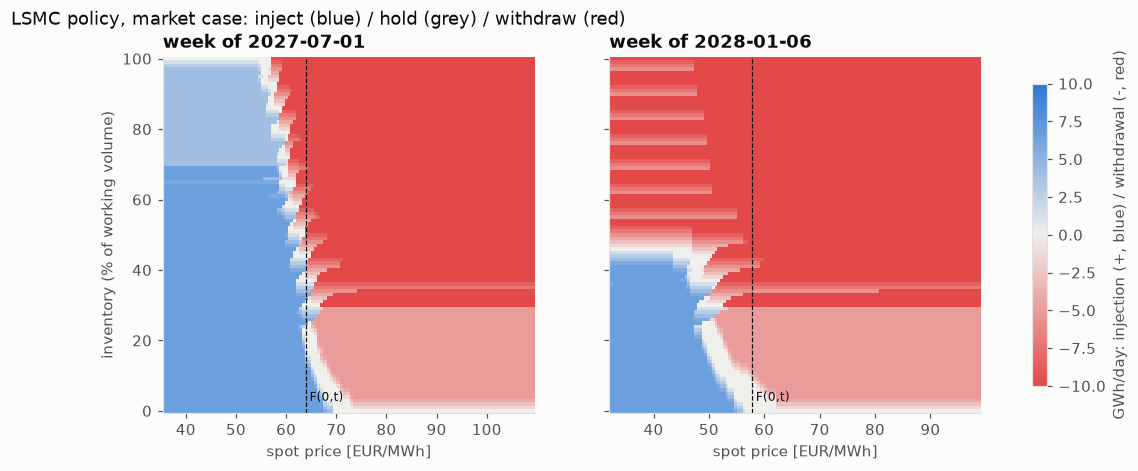

In [6]:
inp, model, res, _, _ = results["market (EEX)"]
vol = inp.contract.working_volume
x_grid = np.linspace(-2.5, 2.5, 121)
inv_grid = np.linspace(0, vol, 101)
dates_pick = [pd.Timestamp("2027-07-01"), pd.Timestamp("2028-01-06")]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
cmap = plotting.diverging_cmap().reversed()  # injection (+) blue, withdrawal (-) red
for ax, d in zip(axes, dates_pick, strict=True):
    k = int(np.searchsorted(inp.dates, d))
    sd = np.sqrt(model.variance(inp.times[k]))
    xs = x_grid * sd
    dv = policy_map(res, inp, model, k, xs, inv_grid)
    spot = model.spot(xs[None, :], [inp.times[k]], [inp.prices[k]])[0]
    rate = dv / inp.days[k] / 1e3
    lim = np.abs(rate).max()
    mesh = ax.pcolormesh(
        spot, 100 * inv_grid / vol, rate.T, cmap=cmap, vmin=-lim, vmax=lim, shading="auto"
    )
    ax.axvline(inp.prices[k], color=plotting.TEXT_PRIMARY, lw=0.8, ls="--")
    ax.text(inp.prices[k], 2, " F(0,t)", fontsize=8, va="bottom")
    ax.set_title(f"week of {inp.dates[k].date()}")
    ax.set_xlabel("spot price [EUR/MWh]")
    ax.grid(False)
axes[0].set_ylabel("inventory (% of working volume)")
cb = fig.colorbar(mesh, ax=axes, shrink=0.85)
cb.set_label("GWh/day: injection (+, blue) / withdrawal (-, red)")
fig.suptitle(
    "LSMC policy, market case: inject (blue) / hold (grey) / withdraw (red)", x=0.01, ha="left"
)
plotting.save_figure(fig, "04_policy_map")
fig

## 4. Convergence

All runs below use the market case (headline) unless stated. Each LSMC value is an out-of-sample estimate with its own
standard error; regression and valuation seeds are fixed and independent.

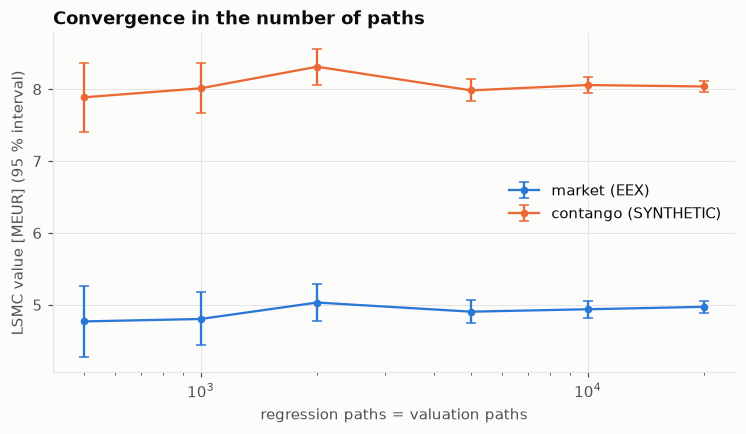

value [MEUR]                         SE [MEUR]             
case  contango (SYNTHETIC) market (EEX) contango (SYNTHETIC) market (EEX)
paths                                                                    
500                  7.887        4.769                0.244        0.251
1000                 8.012        4.803                0.177        0.188
2000                 8.312        5.032                0.127        0.131
5000                 7.983        4.905                0.079        0.082
10000                8.057        4.938                0.056        0.059
20000                8.037        4.972                0.039        0.041

In [7]:
inp_m, model_m = results["market (EEX)"][0], results["market (EEX)"][1]
inp_c, model_c = results["contango (SYNTHETIC)"][0], results["contango (SYNTHETIC)"][1]
rows = []
for n in (500, 1000, 2000, 5000, 10000, 20000):
    for name, inp_, model_ in (
        ("market (EEX)", inp_m, model_m),
        ("contango (SYNTHETIC)", inp_c, model_c),
    ):
        r = run_lsmc(inp_, model_, n, n, 100 + n, 200 + n, n_levels=101)
        rows.append(
            {"case": name, "paths": n, "value [MEUR]": r.value / 1e6, "SE [MEUR]": r.se / 1e6}
        )
conv_paths = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8, 4))
for color, (name, g) in zip(plotting.SERIES, conv_paths.groupby("case", sort=False), strict=False):
    ax.errorbar(
        g["paths"],
        g["value [MEUR]"],
        yerr=1.96 * g["SE [MEUR]"],
        color=color,
        marker="o",
        ms=4,
        capsize=3,
        label=name,
    )
ax.set_xscale("log")
ax.set_xlabel("regression paths = valuation paths")
ax.set_ylabel("LSMC value [MEUR] (95 % interval)")
ax.set_title("Convergence in the number of paths")
ax.legend(loc="center right")
plotting.save_figure(fig, "04_convergence_paths")
display(fig)
conv_paths.pivot(index="paths", columns="case").round(3)

In [8]:
rows = []
for g in (26, 51, 101, 201):
    r = run_lsmc(inp_m, model_m, 5000, 5000, 11, 12, n_levels=g)
    i = solve_dp(inp_m.contract, inp_m.prices, inp_m.days, inp_m.discount, n_levels=g).value
    rc = run_lsmc(inp_c, model_c, 5000, 5000, 11, 12, n_levels=g)
    ic = solve_dp(inp_c.contract, inp_c.prices, inp_c.days, inp_c.discount, n_levels=g).value
    rows.append(
        {
            "grid levels": g,
            "market LSMC": r.value / 1e6,
            "market SE": r.se / 1e6,
            "contango LSMC": rc.value / 1e6,
            "contango SE": rc.se / 1e6,
            "contango intrinsic (same grid)": ic / 1e6,
            "contango extrinsic": (rc.value - ic) / 1e6,
        }
    )
pd.DataFrame(rows).set_index("grid levels").round(3)

,market LSMC,market SE,contango LSMC,contango SE,contango intrinsic (same grid),contango extrinsic
grid levels,,,,,,
26,4.313,0.074,6.950,0.069,5.646,1.304
51,4.620,0.078,7.625,0.075,6.226,1.399
101,4.807,0.080,7.981,0.078,6.434,1.546
201,4.893,0.081,8.157,0.079,6.521,1.636


In [9]:
rows = []
for basis, degree in [("polynomial", d) for d in (1, 2, 3, 4, 5)] + [
    ("laguerre", d) for d in (2, 3, 4)
]:
    r = run_lsmc(inp_m, model_m, 5000, 5000, 21, 22, n_levels=101, basis=basis, degree=degree)
    rows.append(
        {
            "basis": basis,
            "degree": degree,
            "value [MEUR]": r.value / 1e6,
            "SE [MEUR]": r.se / 1e6,
            "in-sample [MEUR]": r.in_sample_value / 1e6,
        }
    )
pd.DataFrame(rows).set_index(["basis", "degree"]).round(3)

value [MEUR]  SE [MEUR]  in-sample [MEUR]
basis      degree                                           
polynomial 1              4.649      0.088             4.789
           2              4.864      0.081             5.006
           3              4.865      0.082             5.011
           4              4.868      0.082             5.017
           5              4.863      0.082             5.018
laguerre   2              4.868      0.080             5.013
           3              4.868      0.082             5.016
           4              4.867      0.082             5.019

In [10]:
rows = []
for i in range(5):
    r = run_lsmc(inp_m, model_m, 5000, 5000, 1000 + i, 2000 + i, n_levels=101)
    rows.append(
        {
            "seed pair": f"({1000 + i}, {2000 + i})",
            "value [MEUR]": r.value / 1e6,
            "SE [MEUR]": r.se / 1e6,
        }
    )
seeds = pd.DataFrame(rows).set_index("seed pair")
sd_seeds, mean_se = seeds["value [MEUR]"].std(), seeds["SE [MEUR]"].mean()
print(f"std across seeds: {sd_seeds:.3f} MEUR; mean SE: {mean_se:.3f} MEUR")
seeds.round(3)

std across seeds: 0.082 MEUR; mean SE: 0.081 MEUR


,value [MEUR],SE [MEUR]
seed pair,,
"(1000, 2000)",5.005,0.081
"(1001, 2001)",4.845,0.081
"(1002, 2002)",4.850,0.081
"(1003, 2003)",5.003,0.082
"(1004, 2004)",4.982,0.081


**Daily steps.** The headline uses weekly decisions for speed. A daily run (201 volume levels, because a day of
injection is smaller than a 101-level grid step) checks the effect of the decision frequency: more frequent decisions
are worth more optionality, while the weekly grid evaluates ratchets only at the start of each week.

In [11]:
rows = []
for name, cfg in cfgs.items():
    model = OneFactorModel.from_config(cfg.model)
    for step, g, n in (("weekly", 201, 3000), ("daily", 201, 3000)):
        inp = build_inputs(cfg, step)
        t0 = time.perf_counter()
        r = run_lsmc(inp, model, n, n, 31, 32, n_levels=g)
        el = time.perf_counter() - t0
        i = solve_lp(inp.contract, inp.prices, inp.days, inp.discount, ratchets=True).value
        rows.append(
            {
                "case": name,
                "step": step,
                "grid": g,
                "paths": n,
                "LSMC [MEUR]": r.value / 1e6,
                "SE [MEUR]": r.se / 1e6,
                "intrinsic MILP [MEUR]": i / 1e6,
                "time (s)": el,
            }
        )
pd.DataFrame(rows).set_index(["case", "step"]).round(3)

grid  paths  LSMC [MEUR]  SE [MEUR]  \
case                 step                                          
market (EEX)         weekly   201   3000        4.980      0.106   
                     daily    201   3000        4.954      0.105   
contango (SYNTHETIC) weekly   201   3000        8.154      0.102   
                     daily    201   3000        8.160      0.101   

                             intrinsic MILP [MEUR]  time (s)  
case                 step                                     
market (EEX)         weekly                  0.000    20.210  
                     daily                   0.000    52.946  
contango (SYNTHETIC) weekly                  6.540    20.282  
                     daily                   6.402    52.940

## 5. Findings

**Headline (weekly, 101 levels, 10,000 + 10,000 paths, seeds 12345 / 67890).**

| | market (EEX 2026-11-17) | contango (SYNTHETIC) |
|---|---|---|
| LSMC total value | **4.90 MEUR** (SE 0.06) | 7.98 MEUR (SE 0.06) |
| intrinsic (same grid) | 0.00 | 6.43 |
| extrinsic | **4.90 (100 %)** | 1.55 (19 %) |
| rolling intrinsic | 3.53 (SE 0.12) | 7.62 (SE 0.13) |

* **Market case.** The curve is backwardated, intrinsic is zero and the storage is worth about 4.9 MEUR of pure
  optionality, i.e. roughly 4.9 EUR per MWh of working volume. Monthly re-optimisation against forwards (rolling
  intrinsic) captures about 70 % of it; weekly decisions against the spot capture the rest. The median inventory
  path stays below 30 %: the policy fills opportunistically when the spot dips below the curve and sells into spikes,
  instead of running a seasonal cycle.
* **Contango case.** The LSMC policy follows the intrinsic profile on average and deviates around it; optionality
  adds about 19 % to the intrinsic value. Same contract and model, very different value structure: the shape of the
  forward curve decides whether storage is a spread trade or an option.
* **Risk.** Unhedged, the realised P&L is wide: market case mean 4.9 MEUR, standard deviation 5.8 MEUR, 5 % quantile
  -4.6 MEUR, about 15 % of paths lose money. This is the risk the delta hedge (notebook 05) addresses.

**Numerical quality.**

* *Lower bound.* The headline is an out-of-sample estimate of a feasible policy, hence a lower bound of the true
  value. The in-sample estimate agrees within Monte Carlo error (4.87 vs 4.90 MEUR), so the regressions do not
  overfit.
* *Monte Carlo error.* Standard errors scale as $1/\sqrt N$ (0.25 MEUR at 500 paths, 0.04 at 20,000). Across five
  independent seed pairs the values have a standard deviation of 0.082 MEUR against a mean reported SE of
  0.081 MEUR: the reported SE is reliable.
* *Basis.* Degree 1 is too poor (4.65 MEUR); from degree 2 on, polynomials and Laguerre agree within 0.01 MEUR.
  Degree 3 is kept.
* *Volume grid: the dominant error.* Values rise with the grid size (market: 4.31, 4.62, 4.81, 4.89 MEUR for 26, 51,
  101, 201 levels), with increments shrinking roughly by half per doubling, i.e. an $O(\Delta)$ bias of the same
  nature as for the intrinsic DP. At 101 levels the grid bias (about 2 %, 0.1-0.2 MEUR) exceeds the Monte Carlo SE;
  extrapolating the increments suggests a limit about 0.1 MEUR above the 201-level value. 101 levels are kept for the
  headline because they meet the run-time target (about 25 s for 10,000 + 10,000 weekly paths) and keep intrinsic and
  LSMC on the same grid; the bias is stated, not hidden.
* *Decision frequency.* With 201 levels, daily and weekly decisions give the same value within SE (market 4.95 vs
  4.98 MEUR). Daily steps add decision flexibility but apply ratchets exactly, weekly steps apply them only at the
  start of each week; the two effects roughly offset here.

**Performance.** 10,000 + 10,000 weekly paths in about 25 s on a laptop without numba, after precomputing the
path-independent action set on the grid (the general move search took about 60 s).